# VAE without conditioning

Este notebook organiza el VAE no condicionado. El modelo aprende la distribucion marginal de `X` y no recibe `C`, calendario, clima ni indicadores como entrada.

La ablation compara distintos valores de beta usando dos criterios de validación: menor validation loss y un criterio generativo basado en coverage, sharpness, RMSE y MMD. Test se usa solamente como análisis posterior.

## Setup

In [1]:
from pathlib import Path
from types import SimpleNamespace
from inspect import signature
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd().resolve()
if current_dir.name == "notebooks" and current_dir.parent.name == "provincias":
    provinces_root = current_dir.parent
elif current_dir.name == "provincias":
    provinces_root = current_dir
elif (current_dir / "provincias").exists():
    provinces_root = current_dir / "provincias"
else:
    raise RuntimeError("No se pudo ubicar la carpeta provincias")

src_dir = provinces_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from model_utils import (
    evaluate_overall_generated_scenarios,
    list_generation_plot_paths,
    load_dates,
    load_result_table,
    load_x_scaler,
    load_x_splits,
    plot_latent_boxplot,
    plot_latent_kl,
    plot_metric_by_province,
    plot_month_metrics,
    plot_nrmse_by_province,
    plot_province_hour_heatmap,
    plot_real_reconstructed_prior_profiles,
    plot_training_history,
    print_split_checks,
    select_device,
    validate_x_splits,
)
from vae_without_conditioning import (
    VAE,
    beta_label,
    encode_distribution_array,
    generate_vae_scenarios,
    load_vae_checkpoint,
    reconstruct_array,
    run_vae_without_conditioning,
)

splits_dir = provinces_root / "data" / "splits"
output_dir = provinces_root / "results" / "vae_without_conditioning"
selected_beta = 0.10
selected_beta_model_path = output_dir / "beta_ablation_models" / f"vae_beta_{beta_label(selected_beta)}.pt"
pretrained_vae_path = selected_beta_model_path if selected_beta_model_path.exists() else output_dir / "vae_best.pt"
if not pretrained_vae_path.exists():
    pretrained_vae_path = None

splits_dir, output_dir, pretrained_vae_path


(PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/data/splits'),
 PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/vae_without_conditioning'),
 PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/vae_without_conditioning/beta_ablation_models/vae_beta_0p1.pt'))

## Datos de entrada

El VAE usa solamente `X_train`, `X_val` y `X_test`. No usa condiciones como input.

In [2]:
X = load_x_splits(splits_dir)
validate_x_splits(X)
print_split_checks(X)

input_summary = pd.DataFrame(
    {
        "split": list(X.keys()),
        "shape": [X[split_name].shape for split_name in X.keys()],
    }
)
display(input_summary)

forward_arguments = list(signature(VAE.forward).parameters)
assert forward_arguments == ["self", "x"]
print("Verificado: el VAE.forward recibe solo x; no recibe calendario, clima ni indicadores como input.")


X_train: shape=(1457, 528), mean=0.0000, std=1.0000, nan_count=0
X_val: shape=(366, 528), mean=0.3081, std=1.1119, nan_count=0
X_test: shape=(485, 528), mean=0.4511, std=1.1791, nan_count=0


,split,shape
0,train,"(1457, 528)"
1,val,"(366, 528)"
2,test,"(485, 528)"


Verificado: el VAE.forward recibe solo x; no recibe calendario, clima ni indicadores como input.


## Ejecutar o cargar resultados

In [3]:
RUN_ANALYSIS = False
RUN_BETA_ABLATION = False

config = SimpleNamespace(
    splits_dir=splits_dir,
    output_dir=output_dir,
    pretrained_vae_path=pretrained_vae_path,
    seed=42,
    device="auto",
    latent_dim=16,
    hidden_dim=256,
    epochs=200,
    batch_size=64,
    learning_rate=1e-3,
    weight_decay=1e-5,
    beta=selected_beta,
    beta_grid=[0.01, 0.05, 0.1, 1.0],
    beta_warmup_epochs=30,
    patience=25,
    min_delta=1e-5,
    n_scenarios=500,
    mmd_max_samples=1000,
    plot_days=4,
    run_beta_ablation=RUN_BETA_ABLATION,
)

if RUN_ANALYSIS or RUN_BETA_ABLATION:
    display(run_vae_without_conditioning(config))
else:
    print(f"Usando resultados guardados en {output_dir}")


Usando resultados guardados en /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/vae_without_conditioning


In [4]:
required_files = [
    output_dir / "config.json",
    output_dir / "training_history.csv",
    output_dir / "reconstruction_metrics.csv",
    output_dir / "metrics_overall.csv",
    output_dir / "metrics_by_month.csv",
    output_dir / "metrics_by_province.csv",
    output_dir / "coverage_by_province_hour.csv",
    output_dir / "rmse_by_province_hour.csv",
    output_dir / "latent_kl_by_dimension.csv",
    output_dir / "vae_beta_ablation.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Faltan resultados. Cambiar RUN_ANALYSIS/RUN_BETA_ABLATION a True. Archivos: {missing_files}")

## Entrenamiento base

El modelo final reportado usa `beta = 0.10`, seleccionado por el criterio generativo de validation en la ablation. Con beta bajo el VAE suele reconstruir mejor, pero puede quedar menos alineado con el prior normal usado para generar muestras; con beta mas alto aumenta la regularizacion del latente hacia `N(0, I)`, lo que puede mejorar el sampling desde el prior aunque empeore la reconstruccion.


,value
batch_size,64
beta,0.1
beta_warmup_epochs,30
data_source,/Users/victoriapersico/Desktop/Ingenieria/Terc...
device,cpu
epochs,200
hidden_dim,256
latent_dim,16
learning_rate,0.001
model,vae_without_conditioning


,split,reconstruction_mse_scaled,total_loss_scaled,stochastic_reconstruction_loss_scaled,kl_loss
0,train,0.075531,0.176114,0.102437,0.736774
1,val,0.147774,0.262993,0.178610,0.843822
2,test,0.214025,0.331184,0.238742,0.924420


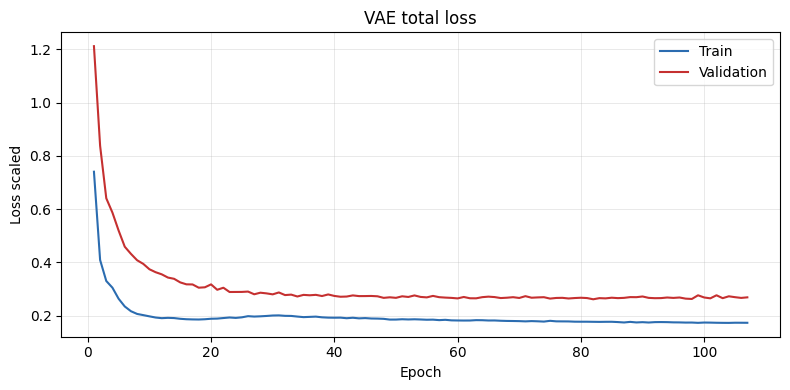

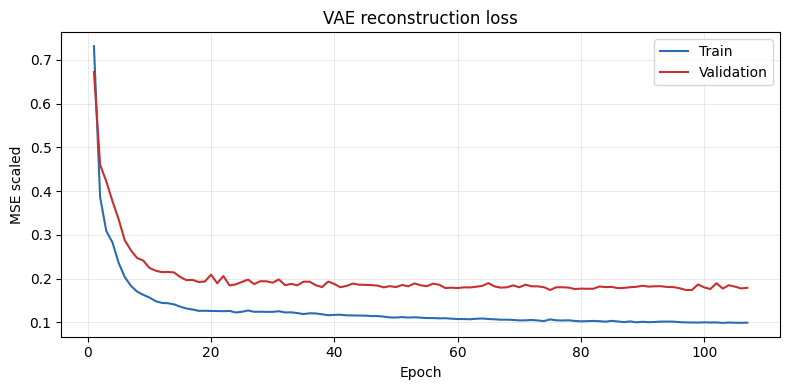

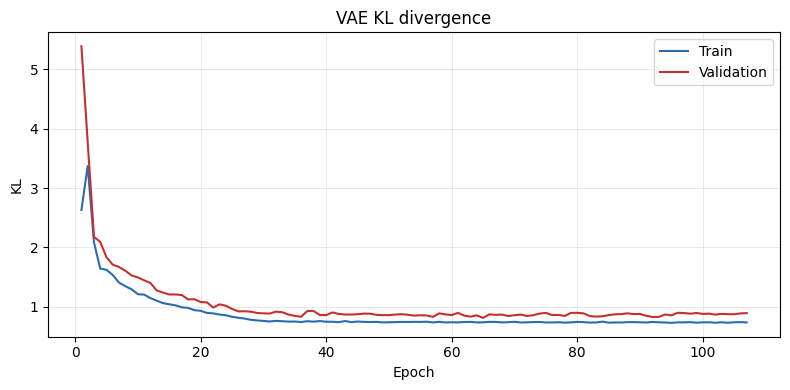

In [5]:
with open(output_dir / "config.json", "r", encoding="utf-8") as file:
    saved_config = json.load(file)

history = load_result_table(output_dir, "training_history.csv")
reconstruction_metrics = load_result_table(output_dir, "reconstruction_metrics.csv")
display(pd.Series(saved_config, name="value").to_frame())
display(reconstruction_metrics)
plot_training_history(history, "train_total", "val_total", "VAE total loss", "Loss scaled")
plot_training_history(history, "train_reconstruction", "val_reconstruction", "VAE reconstruction loss", "MSE scaled")
plot_training_history(history, "train_kl", "val_kl", "VAE KL divergence", "KL")

## Ablation de beta

La tabla prueba `beta = [0.01, 0.05, 0.1, 1.0]`. Cada beta se entrena con `X_train`, se valida con `X_val` y despues se evalua en test. Se reportan dos selecciones hechas solo con validation: menor `val_total_loss` y criterio generativo por cercania a coverage 0.90, menor sharpness, menor RMSE del perfil medio y menor MMD.

,beta,val_reconstruction_loss,val_kl_loss,val_total_loss,val_coverage,val_sharpness,val_rmse_mean_profile,val_mmd,val_coverage_gap,test_reconstruction_loss,test_kl_loss,test_total_loss,test_coverage,test_sharpness,test_rmse_mean_profile,test_mmd,mean_kl,active_latent_dimensions
0,0.01,0.110413,2.394311,0.134356,0.649999,251.929566,297.518860,0.053229,0.250001,0.155089,2.735955,0.182449,0.621704,252.093052,308.647125,0.064780,2.733665,16
1,0.05,0.146819,1.190348,0.206337,0.749845,314.650500,298.862518,0.020781,0.150155,0.199386,1.312193,0.264996,0.717167,314.544242,308.371979,0.025065,1.310057,16
2,0.10,0.176961,0.843822,0.261343,0.767987,327.142803,298.855316,0.018403,0.132013,0.239397,0.924420,0.331839,0.734149,327.526283,308.307587,0.020921,0.922600,15
3,1.00,0.422581,0.195268,0.617848,0.746393,329.231352,298.477966,0.023304,0.153607,0.541901,0.197713,0.739614,0.719787,329.689501,309.140045,0.019837,0.198326,4


,selection_criterion,beta,val_reconstruction_loss,val_kl_loss,val_total_loss,val_coverage,val_sharpness,val_rmse_mean_profile,val_mmd,val_coverage_gap,test_reconstruction_loss,test_kl_loss,test_total_loss,test_coverage,test_sharpness,test_rmse_mean_profile,test_mmd,mean_kl,active_latent_dimensions
0,validation_total_loss,0.01,0.110413,2.394311,0.134356,0.649999,251.929566,297.518860,0.053229,0.250001,0.155089,2.735955,0.182449,0.621704,252.093052,308.647125,0.064780,2.733665,16
1,validation_generative,0.10,0.176961,0.843822,0.261343,0.767987,327.142803,298.855316,0.018403,0.132013,0.239397,0.924420,0.331839,0.734149,327.526283,308.307587,0.020921,0.922600,15


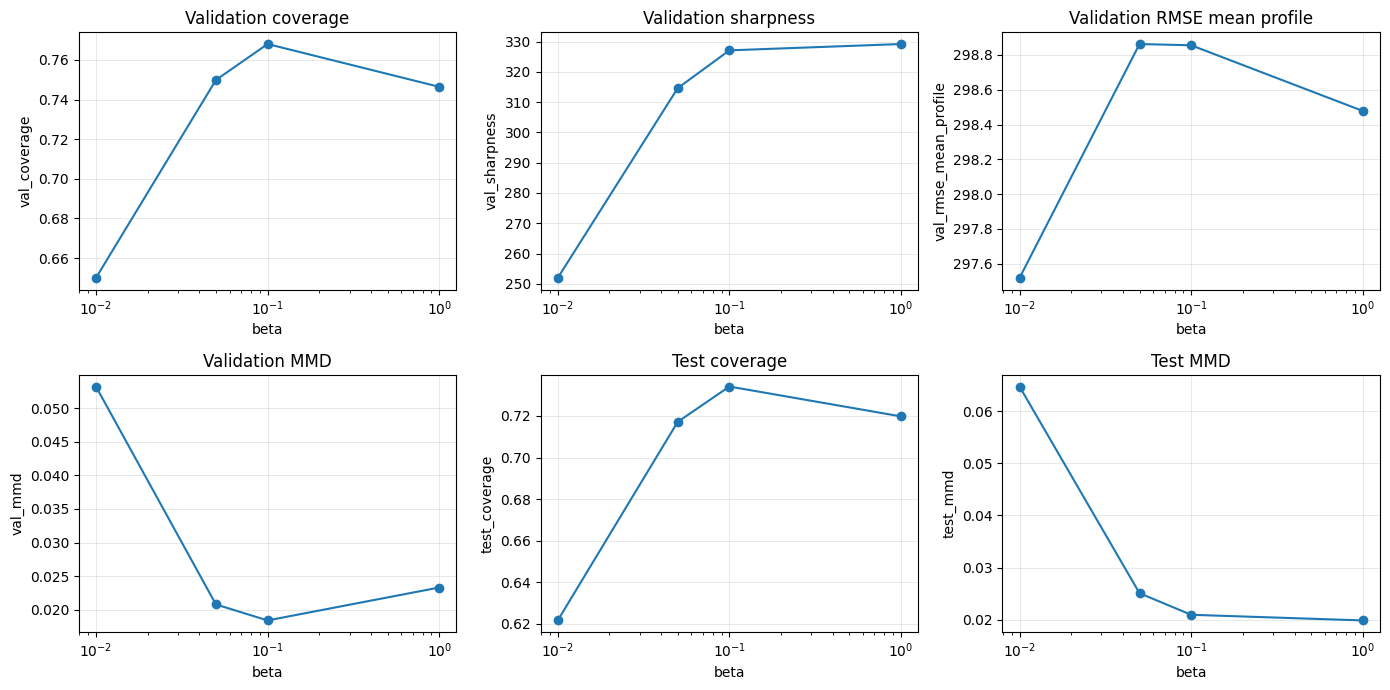

In [6]:
def compute_validation_generation_metrics(
    beta_values: list[float],
    output_dir: Path,
    X_val: np.ndarray,
    x_scaler: object,
    config: SimpleNamespace,
) -> pd.DataFrame:
    """Evaluate prior samples from each beta model on the validation split."""
    device = select_device(config.device)
    rows = []
    ablation_model_dir = output_dir / "beta_ablation_models"
    for beta in beta_values:
        model_path = ablation_model_dir / f"vae_beta_{beta_label(float(beta))}.pt"
        if not model_path.exists():
            raise FileNotFoundError(f"Falta el modelo entrenado para beta={beta}: {model_path}")
        model, _ = load_vae_checkpoint(model_path, device)
        generated_val = generate_vae_scenarios(
            model=model,
            n_days=len(X_val),
            n_scenarios=config.n_scenarios,
            seed=config.seed,
            device=device,
            batch_size=config.batch_size,
        )
        metrics = evaluate_overall_generated_scenarios(
            real_scaled=X_val,
            generated_scaled=generated_val,
            scaler=x_scaler,
            seed=config.seed,
            mmd_max_samples=config.mmd_max_samples,
        ).iloc[0]
        rows.append(
            {
                "beta": float(beta),
                "val_coverage": float(metrics["coverage_p5_p95"]),
                "val_sharpness": float(metrics["sharpness_p5_p95_mwh"]),
                "val_rmse_mean_profile": float(metrics["mean_profile_rmse_mwh"]),
                "val_mmd": float(metrics["mmd_rbf"]),
            }
        )
    return pd.DataFrame(rows)


def complete_beta_ablation_table(
    beta_ablation: pd.DataFrame,
    validation_metrics: pd.DataFrame,
) -> pd.DataFrame:
    """Merge validation generative metrics into the beta ablation table."""
    preserved_columns = [
        "beta",
        "val_reconstruction_loss",
        "val_kl_loss",
        "val_total_loss",
        "val_coverage",
        "val_sharpness",
        "val_rmse_mean_profile",
        "val_mmd",
        "val_coverage_gap",
        "test_reconstruction_loss",
        "test_kl_loss",
        "test_total_loss",
        "test_coverage",
        "test_sharpness",
        "test_rmse_mean_profile",
        "test_mmd",
        "mean_kl",
        "active_latent_dimensions",
    ]
    clean_ablation = beta_ablation.drop(
        columns=[
            "val_coverage",
            "val_sharpness",
            "val_rmse_mean_profile",
            "val_mmd",
            "val_coverage_gap",
        ],
        errors="ignore",
    )
    completed = clean_ablation.merge(validation_metrics, on="beta", how="left")
    completed["val_coverage_gap"] = (completed["val_coverage"] - 0.90).abs()
    return completed[preserved_columns].sort_values("beta").reset_index(drop=True)


def has_validation_generation_metrics(beta_ablation: pd.DataFrame) -> bool:
    """Check whether the ablation table already has validation generative metrics."""
    columns = ["val_coverage", "val_sharpness", "val_rmse_mean_profile", "val_mmd"]
    return set(columns).issubset(beta_ablation.columns) and not beta_ablation[columns].isna().any().any()


def build_beta_selection_comparison(beta_ablation: pd.DataFrame) -> pd.DataFrame:
    """Select beta by validation loss and by validation generative metrics."""
    loss_row = beta_ablation.sort_values("val_total_loss", ascending=True).iloc[0].to_dict()
    generative_row = (
        beta_ablation.sort_values(
            ["val_coverage_gap", "val_sharpness", "val_rmse_mean_profile", "val_mmd"],
            ascending=[True, True, True, True],
        )
        .iloc[0]
        .to_dict()
    )
    rows = []
    for criterion, row in [
        ("validation_total_loss", loss_row),
        ("validation_generative", generative_row),
    ]:
        selected = {"selection_criterion": criterion}
        selected.update(row)
        rows.append(selected)
    columns = [
        "selection_criterion",
        "beta",
        "val_reconstruction_loss",
        "val_kl_loss",
        "val_total_loss",
        "val_coverage",
        "val_sharpness",
        "val_rmse_mean_profile",
        "val_mmd",
        "val_coverage_gap",
        "test_reconstruction_loss",
        "test_kl_loss",
        "test_total_loss",
        "test_coverage",
        "test_sharpness",
        "test_rmse_mean_profile",
        "test_mmd",
        "mean_kl",
        "active_latent_dimensions",
    ]
    comparison = pd.DataFrame(rows)[columns]
    comparison["active_latent_dimensions"] = comparison["active_latent_dimensions"].astype(int)
    return comparison


beta_ablation = load_result_table(output_dir, "vae_beta_ablation.csv")
if has_validation_generation_metrics(beta_ablation):
    beta_ablation = beta_ablation.copy()
    beta_ablation["val_coverage_gap"] = (beta_ablation["val_coverage"] - 0.90).abs()
else:
    x_scaler = load_x_scaler(splits_dir)
    validation_metrics = compute_validation_generation_metrics(
        beta_values=config.beta_grid,
        output_dir=output_dir,
        X_val=X["val"],
        x_scaler=x_scaler,
        config=config,
    )
    beta_ablation = complete_beta_ablation_table(beta_ablation, validation_metrics)

beta_selection_comparison = build_beta_selection_comparison(beta_ablation)

beta_ablation.to_csv(output_dir / "vae_beta_ablation.csv", index=False)
beta_selection_comparison.to_csv(output_dir / "vae_beta_selection_comparison.csv", index=False)

loss_selected = beta_selection_comparison.loc[
    beta_selection_comparison["selection_criterion"] == "validation_total_loss"
].iloc[0]
generative_selected = beta_selection_comparison.loc[
    beta_selection_comparison["selection_criterion"] == "validation_generative"
].iloc[0]
selection_summary = {
    "selected_beta": float(loss_selected["beta"]),
    "selection_rule": "lowest validation total loss",
    "generative_selection_rule": (
        "validation coverage closest to 0.90, then lower sharpness, "
        "lower mean profile RMSE and lower MMD"
    ),
    "selected_beta_by_val_total_loss": float(loss_selected["beta"]),
    "selected_beta_by_validation_generative": float(generative_selected["beta"]),
}
(output_dir / "vae_beta_ablation_selection.json").write_text(
    json.dumps(selection_summary, indent=2),
    encoding="utf-8",
)

display(beta_ablation)
display(beta_selection_comparison)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
plots = [
    ("val_coverage", "Validation coverage"),
    ("val_sharpness", "Validation sharpness"),
    ("val_rmse_mean_profile", "Validation RMSE mean profile"),
    ("val_mmd", "Validation MMD"),
    ("test_coverage", "Test coverage"),
    ("test_mmd", "Test MMD"),
]
for ax, (column, title) in zip(axes.ravel(), plots):
    ax.plot(beta_ablation["beta"], beta_ablation[column], marker="o")
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("beta")
    ax.set_ylabel(column)
    ax.grid(linewidth=0.4, alpha=0.5)
fig.tight_layout()
plt.show()


El beta con menor `val_total_loss` no necesariamente es el mejor generativamente, porque cada beta cambia el peso del termino KL en la funcion objetivo. Beta bajo suele favorecer reconstruccion, pero puede samplear peor desde el prior `N(0, I)`. Beta mas alto puede empeorar reconstruccion y aun asi mejorar coverage o MMD si alinea mejor el posterior con el prior. La seleccion por `val_total_loss` responde al objetivo de entrenamiento; la seleccion generativa por validation esta mas alineada con producir escenarios plausibles. Test queda solamente como reporte final y no se usa para elegir beta. El VAE sigue siendo no condicionado: no recibe clima, calendario ni indicadores, y no genera escenarios adaptados a un dia especifico.

Las metricas detalladas por mes, provincia y hora corresponden al modelo no condicionado con `beta = 0.10`, seleccionado por el criterio generativo de validation. La ablation mantiene por separado el mejor beta por `val_total_loss` (`0.01`) y el mejor beta por criterio generativo (`0.10`).


## Evaluacion final con beta = 0.10


In [7]:
overall_metrics = load_result_table(output_dir, "metrics_overall.csv")
display(overall_metrics.T.rename(columns={0: "value"}))

row = overall_metrics.iloc[0]
print(f"Coverage P5-P95: {row['coverage_p5_p95']:.3f}")
print(f"Sharpness promedio P5-P95: {row['sharpness_p5_p95_mwh']:.2f} MWh")
print(f"RMSE del perfil medio: {row['mean_profile_rmse_mwh']:.2f} MWh")
print(f"MMD RBF: {row['mmd_rbf']:.6f}")

,value
coverage_p5_p95,0.734149
sharpness_p5_p95_mwh,327.526283
mean_profile_rmse_mwh,308.307587
mmd_rbf,0.020921
n_days,485.000000
n_scenarios_per_day,500.000000


Coverage P5-P95: 0.734
Sharpness promedio P5-P95: 327.53 MWh
RMSE del perfil medio: 308.31 MWh
MMD RBF: 0.020921


## Evaluacion por mes, provincia y hora

,mes,coverage,sharpness,rmse_mean_profile,n_days
0,1,0.531586,326.755701,358.558014,62
1,2,0.490801,328.110440,334.972839,56
2,3,0.781219,327.139228,295.702332,62
3,4,0.823201,328.112306,233.162842,60
4,5,0.826307,327.626086,262.610596,31
5,6,0.811174,327.079282,412.767883,30
6,7,0.783113,329.587497,393.790405,31
7,8,0.883370,326.458925,245.947601,31
8,9,0.845896,328.767394,209.724258,30
9,10,0.860093,327.506541,237.088348,31


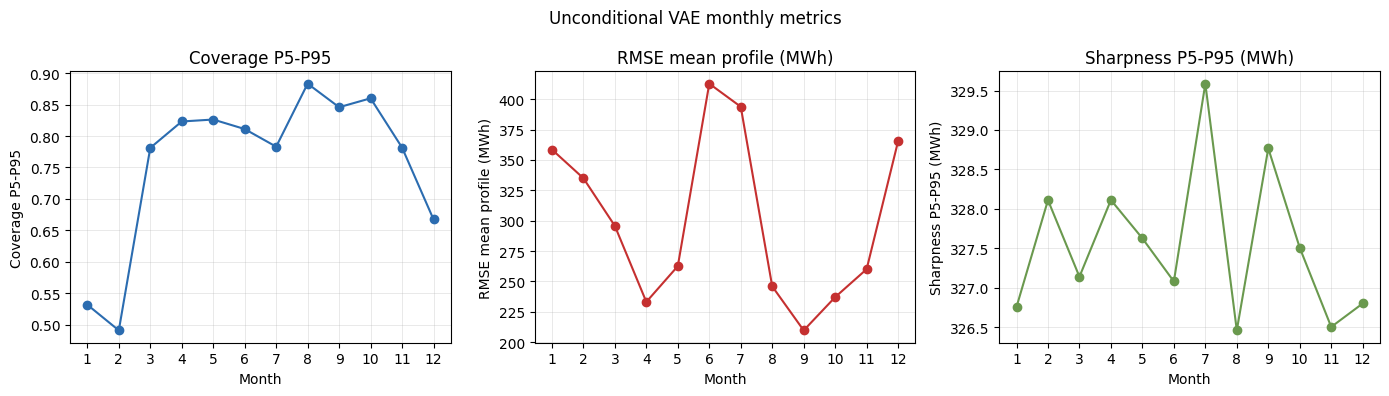

,province,rmse,mean_profile_rmse_mwh,mean_demand,mean_demand_mwh,nrmse,coverage,coverage_p5_p95,sharpness,sharpness_p5_p95_mwh,mmd_rbf
20,sgo_del_estero,96.752159,96.752159,241.469025,241.469025,0.400681,0.731357,0.731357,161.539927,161.539927,0.062429
2,chaco,151.074936,151.074936,401.316223,401.316223,0.376449,0.733247,0.733247,270.575816,270.575816,0.056154
7,formosa,68.724701,68.724701,184.996826,184.996826,0.371491,0.720962,0.720962,131.216869,131.216869,0.065108
5,corrientes,120.506927,120.506927,375.334198,375.334198,0.321066,0.723711,0.723711,218.190450,218.190450,0.050055
16,san_juan,79.158638,79.158638,285.251984,285.251984,0.277504,0.712285,0.712285,152.507489,152.507489,0.046990
21,tucuman,96.392395,96.392395,392.474487,392.474487,0.245602,0.773711,0.773711,186.434590,186.434590,0.022908
6,entre_rios,110.877037,110.877037,468.636078,468.636078,0.236595,0.761082,0.761082,229.234175,229.234175,0.028946
10,la_rioja,44.183903,44.183903,186.800217,186.800217,0.236530,0.747938,0.747938,92.163209,92.163209,0.030473


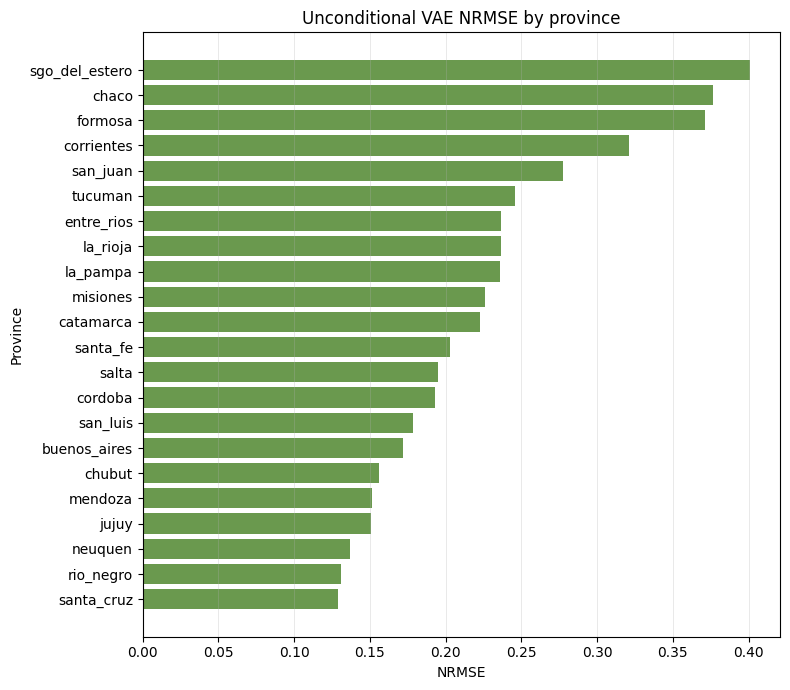

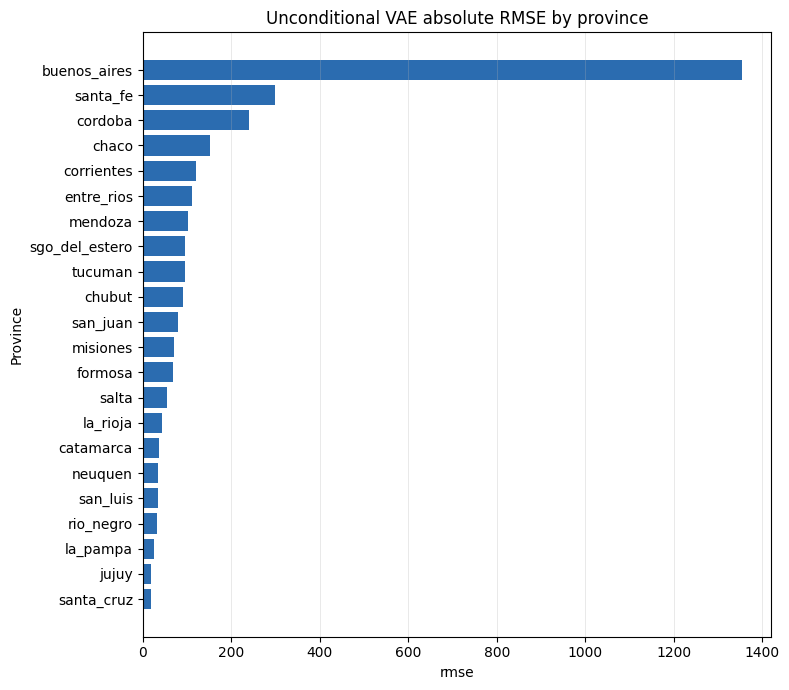

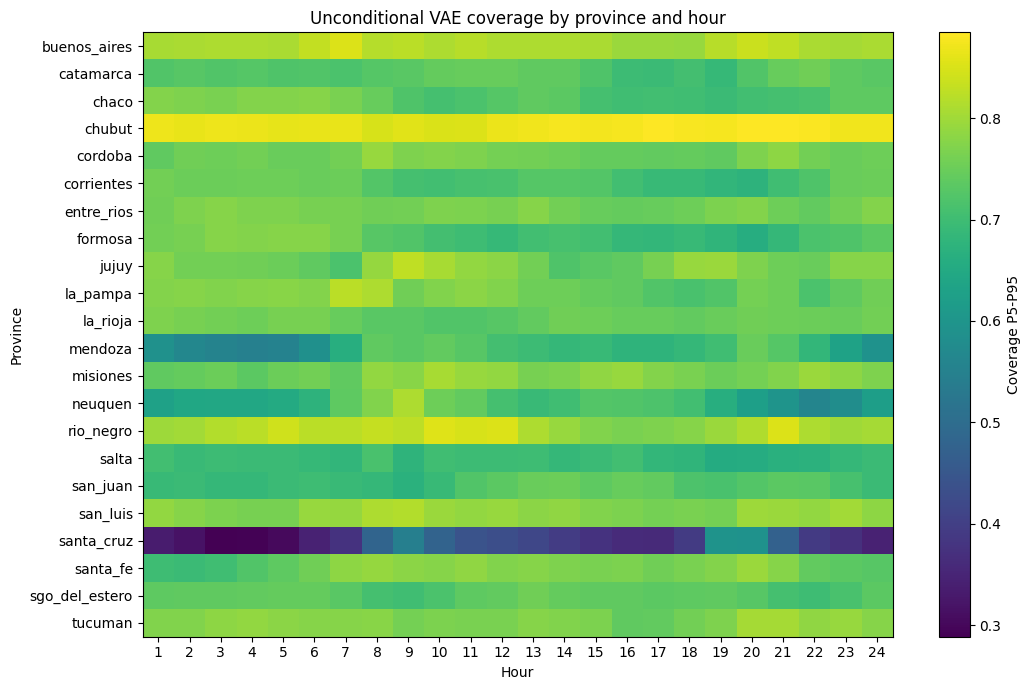

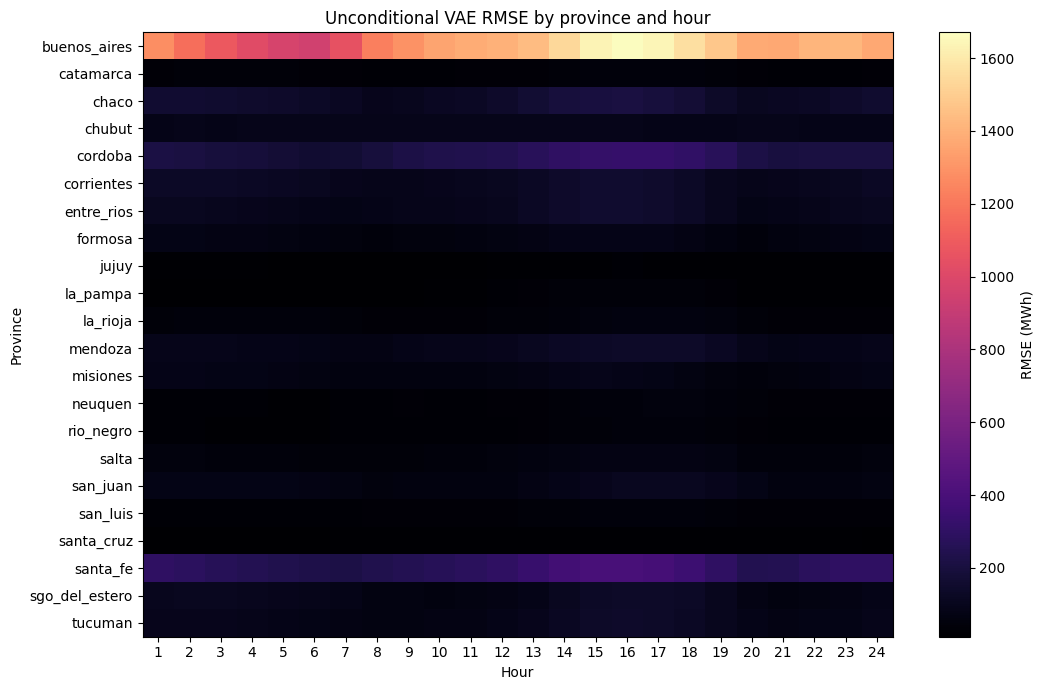

In [8]:
metrics_by_month = load_result_table(output_dir, "metrics_by_month.csv")
province_metrics = load_result_table(output_dir, "metrics_by_province.csv")
coverage_by_hour = pd.read_csv(output_dir / "coverage_by_province_hour.csv", index_col=0)
rmse_by_hour = pd.read_csv(output_dir / "rmse_by_province_hour.csv", index_col=0)

display(metrics_by_month)
plot_month_metrics(metrics_by_month, "Unconditional VAE monthly metrics")
display(province_metrics.sort_values("nrmse", ascending=False).head(8))
plot_nrmse_by_province(province_metrics, "Unconditional VAE NRMSE by province")
plot_metric_by_province(province_metrics, "rmse", "Unconditional VAE absolute RMSE by province")
plot_province_hour_heatmap(coverage_by_hour, "Unconditional VAE coverage by province and hour", "Coverage P5-P95", "viridis")
plot_province_hour_heatmap(rmse_by_hour, "Unconditional VAE RMSE by province and hour", "RMSE (MWh)", "magma")

## Diagnostico del espacio latente

,latent_dim,mu_mean,mu_std,logvar_mean,std_mean,kl
0,1,0.050094,0.242816,-0.117876,0.944337,0.037009
1,2,0.610079,1.034211,-3.139469,0.213597,1.814586
2,3,0.141370,0.247142,-0.105927,0.949023,0.044391
3,4,0.431924,0.845184,-2.166974,0.343487,1.094645
4,5,0.056522,0.300305,-0.126076,0.940128,0.052762
5,6,0.066911,0.998205,-1.876057,0.415048,1.033576
6,7,-0.006411,0.263689,-0.078905,0.961948,0.037508
7,8,0.021344,0.160367,-0.059008,0.971488,0.015032
8,9,-0.586558,0.757412,-1.004298,0.621866,0.664141
9,10,0.238551,1.024362,-2.134154,0.350481,1.183750


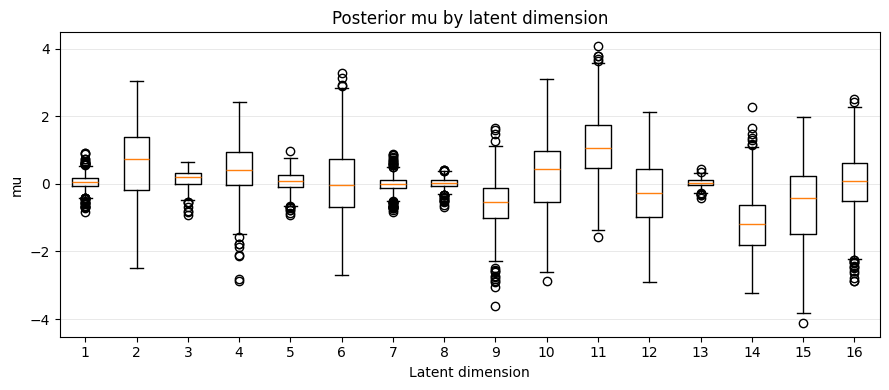

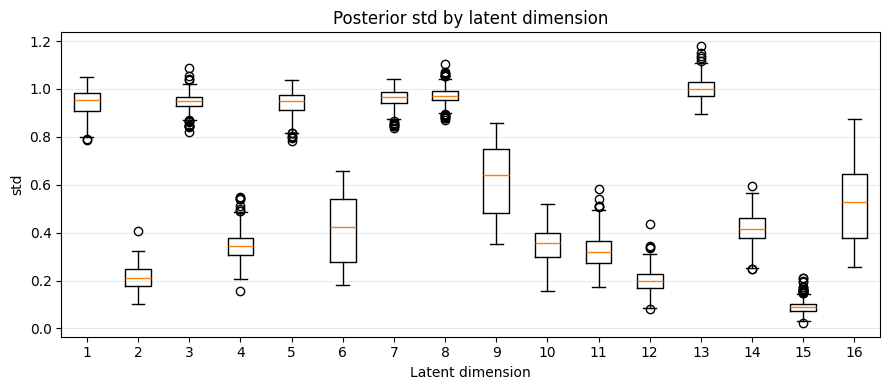

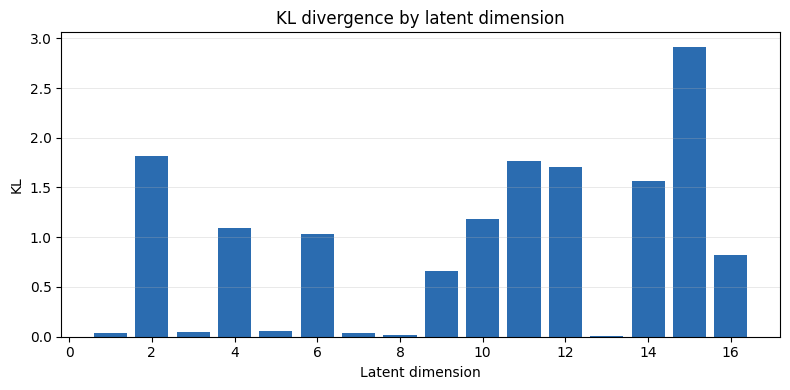

Dimensiones activas con KL > 0.01: 15 de 16


In [9]:
device = select_device("auto")
model, checkpoint = load_vae_checkpoint(output_dir / "vae_best.pt", device)
mu_test, logvar_test = encode_distribution_array(model, X["test"], device, batch_size=64)
std_test = np.exp(0.5 * logvar_test)
latent_kl = load_result_table(output_dir, "latent_kl_by_dimension.csv")

display(latent_kl)
plot_latent_boxplot(mu_test, "Posterior mu by latent dimension", "mu")
plot_latent_boxplot(std_test, "Posterior std by latent dimension", "std")
plot_latent_kl(latent_kl)
active_dims = int((latent_kl["kl"] > 0.01).sum())
print(f"Dimensiones activas con KL > 0.01: {active_dims} de {len(latent_kl)}")

## Reconstrucciones vs muestras del prior

Una buena reconstruccion no garantiza buenas muestras generativas si el posterior aprendido no coincide bien con el prior.

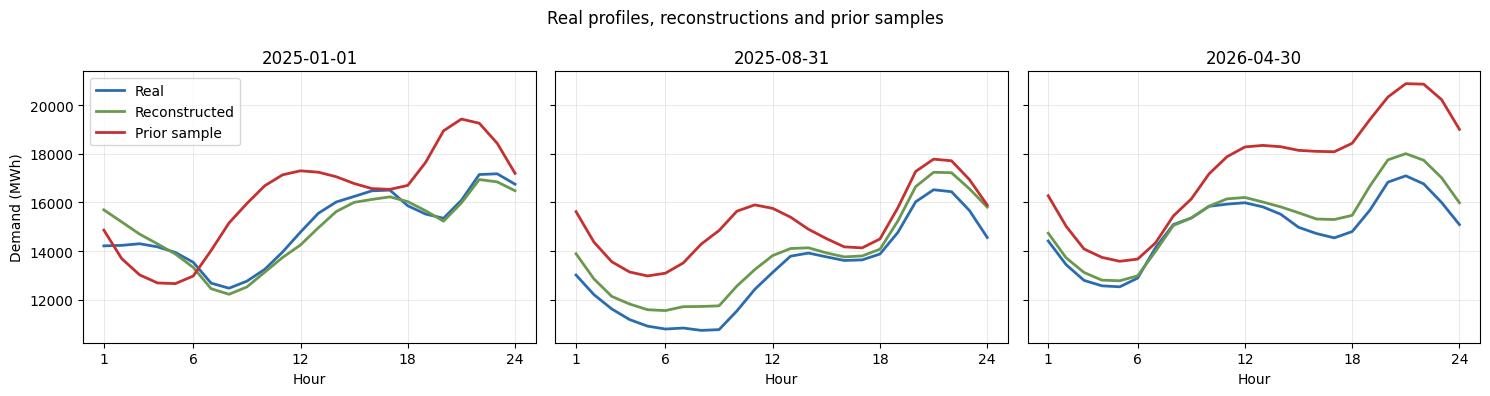

In [10]:
dates_test = load_dates(splits_dir, "test")
x_scaler = load_x_scaler(splits_dir)
selected_indices = np.linspace(0, len(X["test"]) - 1, num=3, dtype=int)
real_sample = X["test"][selected_indices]
reconstructed_sample = reconstruct_array(model, real_sample, device, batch_size=64)
prior_sample = generate_vae_scenarios(model, len(selected_indices), 1, 42, device, 64).reshape(len(selected_indices), -1)
plot_real_reconstructed_prior_profiles(real_sample, reconstructed_sample, prior_sample, x_scaler, dates_test[selected_indices])

## Perfiles reales vs generados

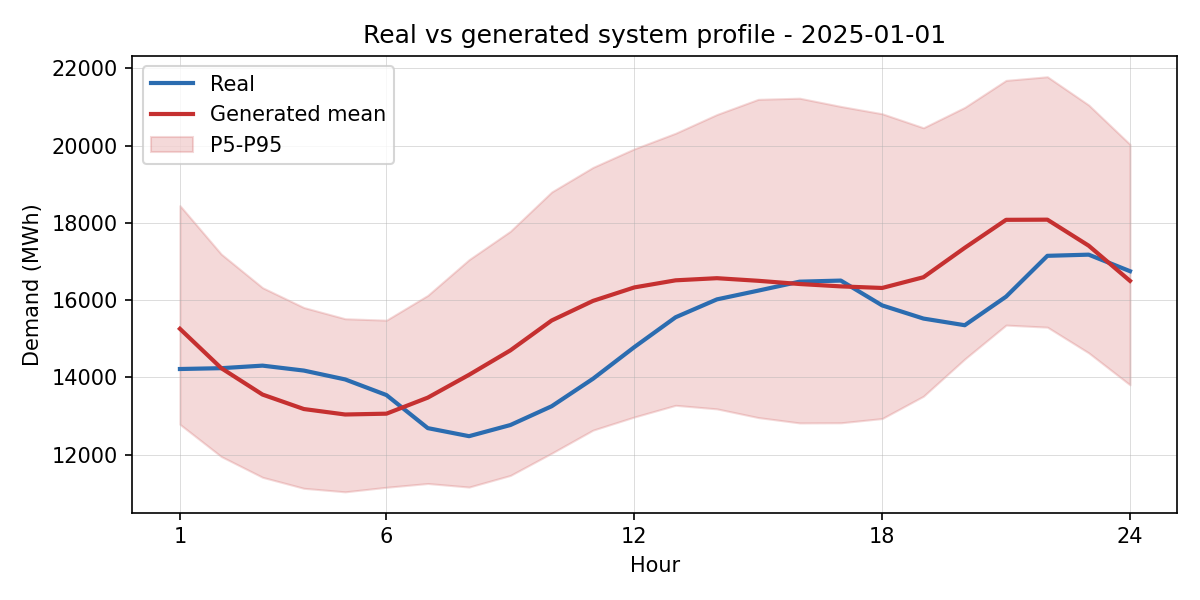

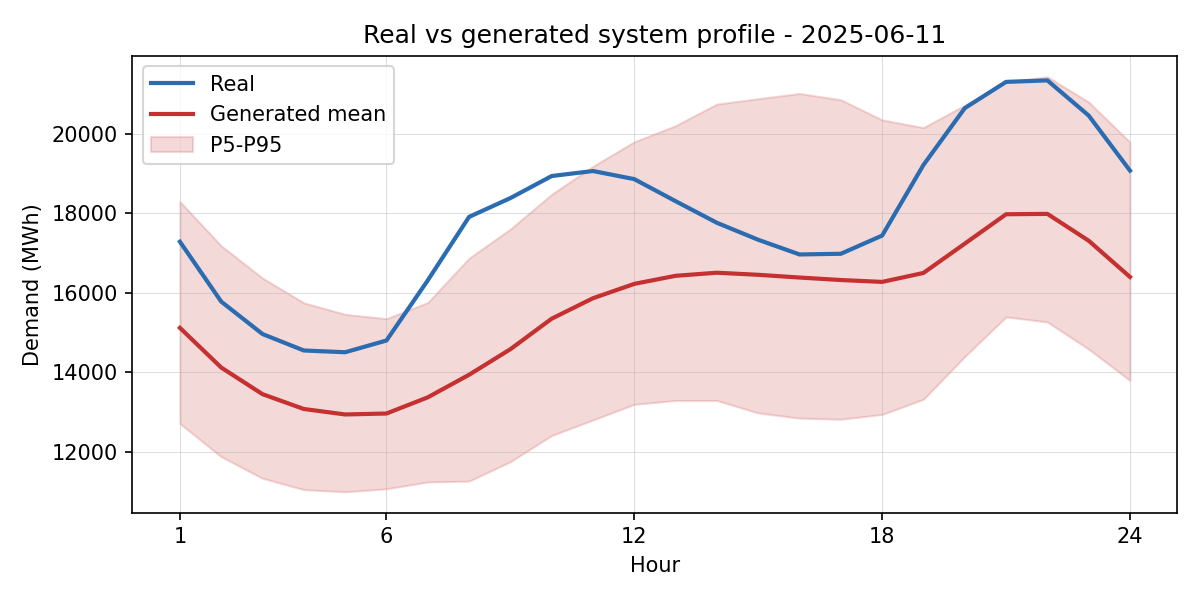

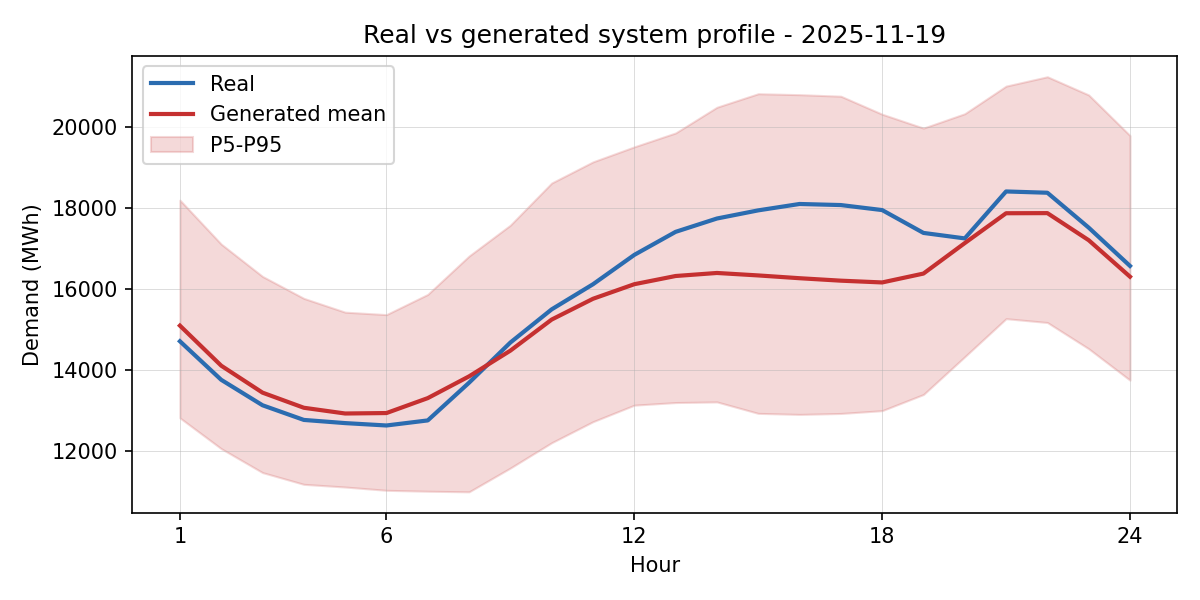

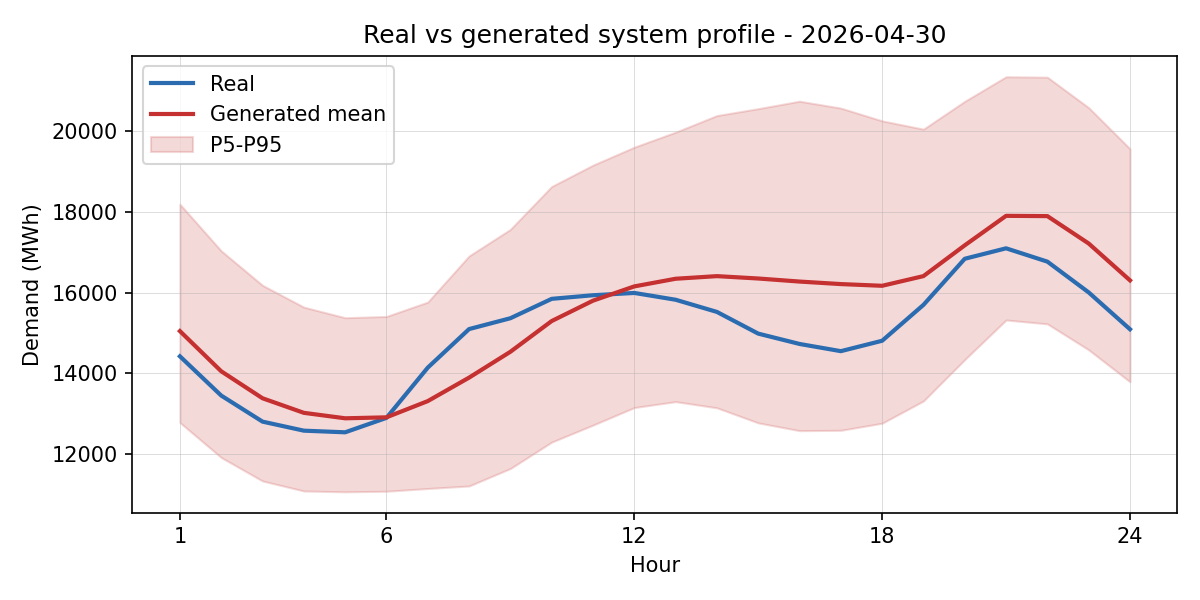

In [11]:
for plot_path in list_generation_plot_paths(output_dir, max_plots=4):
    display(Image(filename=str(plot_path)))

## Conclusion

La ablation muestra el trade-off de beta desde dos lecturas de validation. El criterio por `val_total_loss` elige `beta = 0.01`, que favorece la reconstruccion dentro del objetivo de entrenamiento. El criterio generativo elige `beta = 0.10`, que sacrifica parte de la reconstruccion pero regulariza mas el latente hacia el prior y mejora las muestras desde `N(0, I)` segun coverage y MMD de validation. Test se reporta despues para comparar los betas seleccionados, pero no participa en la decision. Este VAE sigue siendo una ablation marginal: no conoce calendario, clima ni indicadores, por lo que no genera escenarios adaptados a dias especificos; esa capacidad corresponde al CVAE condicionado.
